# 87 · Pretrained CLIP, zero-shot, on MuJoCo renders: what it gets right (objects, colors) and wrong (relations, state)

In [1]:
import numpy as np, torch, matplotlib.pyplot as plt
from transformers import CLIPModel, CLIPProcessor
from vlacourse import TableTop, COLORS, show_images

device = "cuda" if torch.cuda.is_available() else "cpu"
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

@torch.no_grad()
def scores(image, texts):
    inp = proc(text=texts, images=image, return_tensors="pt", padding=True).to(device)
    return model(**inp).logits_per_image.softmax(-1)[0].cpu().numpy()

def crop(img, mask, pad=6):
    ys, xs = np.nonzero(mask)
    return img[max(0, ys.min() - pad): ys.max() + pad, max(0, xs.min() - pad): xs.max() + pad]

~/anaconda3/envs/vla/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 71278.10it/s]

In [2]:
env = TableTop(cameras=("front",), image_size=(224, 224), seed=0)
img = env.reset(seed=5)["images"]["front"]
texts = ["a robot arm and colored blocks on a table", "a kitchen with a refrigerator", "a dog on grass", "a car on a road"]
print({t: round(float(p), 3) for t, p in zip(texts, scores(img, texts))})

{'a robot arm and colored blocks on a table': 0.996, 'a kitchen with a refrigerator': 0.003, 'a dog on grass': 0.0, 'a car on a road': 0.002}


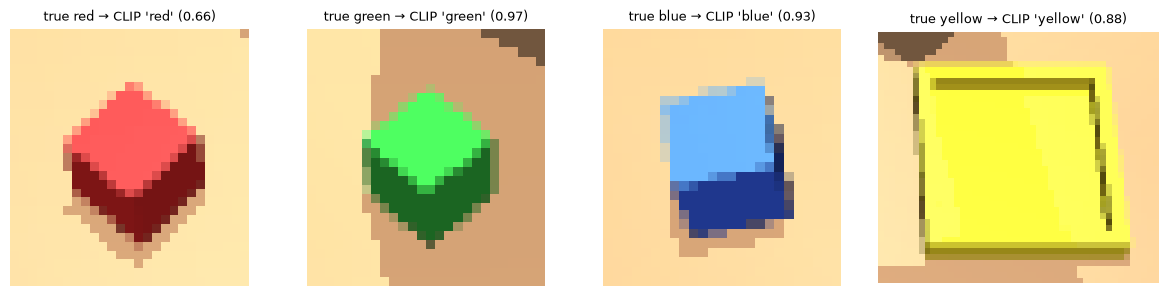

In [3]:
seg = env.render("front", segmentation=True)
color_names = list(COLORS)
crops, results = [], []
for c in env.cube_colors + env.tray_colors:
    kind = "cube" if c in env.cube_colors else "tray"
    gids = [g for g in range(env.model.ngeom) if env.model.body(env.model.geom_bodyid[g]).name == f"{kind}_{c}"]
    mask = np.isin(seg[..., 0], gids) & (seg[..., 1] == 5)
    if mask.sum() < 20:
        continue
    cr = crop(img, mask); crops.append(cr)
    p = scores(cr, [f"a photo of a {k} block" for k in color_names])
    results.append((c, color_names[int(p.argmax())], p.max()))
show_images(crops, [f"true {c} → CLIP '{pred}' ({p:.2f})" for c, pred, p in results], cols=len(crops))

In [4]:
trials, correct = 0, 0
for s in range(40):
    env.reset(seed=100 + s, task=None)
    cube, tray = env.cube_colors[0], env.tray_colors[0]
    in_tray = s % 2 == 0
    if in_tray:
        import mujoco
        adr = env.model.jnt_qposadr[env.model.joint(f"cube_{cube}").id]
        env.data.qpos[adr:adr + 3] = env.tray_pos(tray) + [0, 0, 0.03]
        for _ in range(100):
            mujoco.mj_step(env.model, env.data)
    im = env.render("front")
    p = scores(im, [f"the {cube} cube is inside the {tray} tray", f"the {cube} cube is outside the {tray} tray"])
    correct += int((p[0] > p[1]) == in_tray); trials += 1
print(f"'is the {cube} cube in the {tray} tray?' zero-shot accuracy: {correct / trials:.2f} (chance 0.5) -> relations and state are weak in CLIP")

'is the red cube in the yellow tray?' zero-shot accuracy: 0.50 (chance 0.5) -> relations and state are weak in CLIP
